# 선형회귀 파이프라인 모듈화

## my_ols.py 작업

### 1. import 추가

In [1]:
from IPython.display import display, Markdown

### 2. 전처리 파이프라인 — 플래그대로 전처리한 뒤 회귀모델을 적합한다

In [2]:
def fit_pipeline(data, y, nominal_cols=None, *,
                 # --- 1) 명목형 라벨링 (문자열 -> 정수) ---
                 labeling=True,
                 # --- 2) 더미변수 인코딩 ---
                 encode=True,
                 # --- 3) 로그 변환 (우측꼬리 log1p / 좌측꼬리 반사 후 log1p) ---
                 log=False,
                 log_target=True,
                 log_columns=None,
                 reflect_columns=None,
                 # --- 4) 이상치 대체 (IQR 경계값, 행 삭제 없음) ---
                 outlier=False,
                 # --- 5) 다중공선성 제거 (VIF) ---
                 vif=False,
                 vif_threshold=10.0,
                 # --- 6) 정규화 ---
                 scale=False,
                 scale_method='standard',
                 # --- 7) 모델 적합 ---
                 backward=True,
                 alpha=0.05,
                 # --- 기타 ---
                 name=None,
                 save_path=None,
                 verbose=False):
    """플래그로 지정한 전처리를 수행한 뒤 회귀모델을 적합한다.

    파라미터의 나열 순서가 곧 처리 순서이며, 강의 분석 흐름도의 단계 순서와 같다.
    결측치는 없다고 전제한다.

        라벨링 -> 더미 인코딩 -> 로그변환 -> 이상치 대체
        -> 다중공선성 제거 -> 정규화 -> 모델 적합

    각 단계는 대상 컬럼을 명시해서 넘긴다(연속형/명목형). 두 목록이 겹치지 않으므로
    더미 인코딩과 로그·이상치·정규화는 서로의 대상을 건드리지 않는다.

    Args:
        data (DataFrame): 독립변수와 종속변수를 모두 포함하는 데이터프레임.
        y (str): 종속변수로 사용할 컬럼명.
        nominal_cols (list): 명목형 컬럼명 리스트. None이면 타입 자동 선택 (기본값: None).
        labeling (bool): 명목형 라벨링(문자열 -> 정수) 수행 여부 (기본값: True).
        encode (bool): 더미변수 인코딩 수행 여부 (기본값: True).
        log (bool): 로그 변환 수행 여부 (기본값: False).
        log_target (bool): 로그 변환 대상에 종속변수를 포함할지 여부 (기본값: True).
        log_columns (list): 우측 꼬리(log1p) 변환 대상. None이면 자동 선정 (기본값: None).
        reflect_columns (list): 좌측 꼬리(반사 후 log1p) 변환 대상 (기본값: None).
        outlier (bool): 이상치를 IQR 경계값으로 대체할지 여부 (기본값: False).
        vif (bool): 다중공선성 제거 수행 여부 (기본값: False).
        vif_threshold (float): VIF 임계값 (기본값: 10.0).
        scale (bool): 정규화 수행 여부 (기본값: False).
        scale_method (str): 사용할 스케일러 이름 (기본값: 'standard').
        backward (bool): 후진소거법 수행 여부 (기본값: True).
        alpha (float): 후진소거법의 변수 제거 기준 유의수준 (기본값: 0.05).
        name (str): 모델을 구분할 이름. 결과 객체의 `name_` 속성이 된다 (기본값: None).
        save_path (str): 전처리 완료 데이터의 저장 경로 (.xlsx/.xls/.csv) (기본값: None).
        verbose (bool): 단계별 전처리 내역 출력 여부 (기본값: False).

    Returns:
        적합이 완료된 회귀분석 결과 객체. 보고에 필요한 정보를 아래 속성으로 함께 붙여
        반환하므로, 보고 함수에 그대로 넘겨 쓸 수 있다.
            - `log1p_y_` (bool) / `log1p_x_` (list): 로그 변환 정보
            - `data_` (DataFrame): 전처리가 끝난 데이터 (β·VIF 계산용)
            - `use_hc3_` (bool): 등분산 위배 여부. `auto_ols`가 붙여 준다

    Raises:
        KeyError: 종속변수나 `nominal_cols`의 컬럼이 `data`에 없는 경우.
        ValueError: 숫자가 아닌 컬럼이나 결측치가 남아 있는 경우,
            또는 `save_path`의 확장자가 지원 형식이 아닌 경우.
    """
    # --- 0) 입력 검증 및 컬럼 역할 정리 ---
    if y not in data.columns:
        raise KeyError(f"종속변수 '{y}'가 데이터프레임의 컬럼에 존재하지 않습니다.")

    df = data.copy()    # 원본을 보존하기 위해 복사본으로 작업

    # 명목형 컬럼: 지정이 없으면 category/object 타입을 자동으로 선택한다
    if nominal_cols is None:
        nominal_cols = list(df.select_dtypes(include=['category', 'object']).columns)
    else:
        missing = []
        for c in nominal_cols:
            if c not in df.columns:
                missing.append(c)

        if missing:
            raise KeyError(f'df 에 존재하지 않는 컬럼입니다: {missing}')

    # 종속변수는 명목형 목록에서 제외한다 (회귀의 종속변수는 연속형이어야 한다)
    nominals = []
    for c in nominal_cols:
        if c != y:
            nominals.append(c)

    nominal_cols = nominals

    # 연속형 독립변수: 수치형 중에서 종속변수와 명목형을 뺀 나머지
    # 로그변환·이상치대체·다중공선성·정규화의 대상이 되며, 단계마다 갱신된다
    continuous = []
    for c in df.select_dtypes(include='number').columns:
        if c != y and c not in nominal_cols:
            continuous.append(c)

    # 로그 변환 정보 (반환되는 fit 객체에 붙여 계수 해석에 사용한다)
    log1p_y = False
    log1p_x = []

    if verbose:
        print(f'대상: {df.shape[0]}행 x {df.shape[1]}열 | 종속변수: {y}')
        print(f'명목형: {nominal_cols}')
        print(f'연속형: {continuous}')

    # --- 1) 명목형 라벨링 ---
    if labeling and nominal_cols:
        if verbose:
            print(f'\n[1] 명목형 라벨링')

        df = my_prep.labeling(df, columns=nominal_cols, verbose=verbose)

    # --- 2) 더미변수 인코딩 ---
    if encode and nominal_cols:
        if verbose:
            print(f'\n[2] 더미변수 인코딩')

        df = my_prep.dummies(df, columns=nominal_cols, drop_first=True, verbose=verbose)

    # --- 3) 로그 변환 ---
    if log:
        # 종속변수의 포함 여부는 log_target 이 결정한다
        scope = list(continuous)

        if log_target:
            scope.append(y)

        # 변환 대상을 지정하지 않았다면 왜도·첨도를 근거로 자동 선정한다
        if log_columns is None:
            desc = my_qtcheck.numerical_summary(df, columns=scope)
            log_columns = desc.index[desc['log_need'] == 'log1p'].tolist()

            if reflect_columns is None:
                reflect_columns = desc.index[desc['log_need'] == 'reverse_log1p'].tolist()

        if reflect_columns is None:
            reflect_columns = []

        if verbose:
            print(f'\n[3] 로그 변환')

        df = my_prep.log_transform(df, log_columns=log_columns,
                                   reflect_columns=reflect_columns, verbose=verbose)

        # 반사 변환(reflect)한 컬럼은 대소 관계가 뒤집혀 해석 방식이 다르므로
        # log1p 로 보고할 목록에는 포함하지 않는다
        log1p_y = y in log_columns

        for c in log_columns:
            if c != y:
                log1p_x.append(c)

    # --- 4) 이상치 대체 ---
    # 연속형 독립변수만 대상으로 한다 (종속변수를 자르면 예측 대상 자체가 왜곡된다)
    if outlier and continuous:
        if verbose:
            print(f'\n[4] 이상치 대체')

        df = my_prep.replace_outlier(df, columns=continuous, verbose=verbose)

    # --- 5) 다중공선성 제거 ---
    if vif and continuous:
        if verbose:
            print(f'\n[5] 다중공선성 제거 (VIF >= {vif_threshold})')

        df = my_prep.reduce_vif(df, columns=continuous,
                                threshold=vif_threshold, verbose=verbose)

        # 제거된 변수를 반영해야 이후 정규화 단계에서 없는 컬럼을 찾지 않는다
        survived = []
        for c in continuous:
            if c in df.columns:
                survived.append(c)

        continuous = survived

    # --- 6) 정규화 ---
    if scale and continuous:
        if verbose:
            print(f'\n[6] 정규화')

        df = my_prep.scaling(df, columns=continuous,
                             method=scale_method, verbose=verbose)

    # --- 7) 전처리 완료 데이터 저장 (선택) ---
    if save_path:
        folder = os.path.dirname(save_path)
        if folder:
            # 경로에 없는 폴더가 있으면 만들어 준다
            os.makedirs(folder, exist_ok=True)

        ext = os.path.splitext(save_path)[1].lower()

        if ext in ('.xlsx', '.xls'):
            df.to_excel(save_path, index=False)
        elif ext == '.csv':
            # 엑셀에서 한글이 깨지지 않도록 BOM 을 포함해 저장한다
            df.to_csv(save_path, index=False, encoding='utf-8-sig')
        else:
            raise ValueError(f"지원하지 않는 저장 형식입니다: '{ext}' "
                             f"(사용 가능: .xlsx, .xls, .csv)")

        if verbose:
            print(f'\n전처리 데이터 저장: {save_path} '
                  f'({df.shape[0]}행 x {df.shape[1]}열)')

    # --- 8) 모델 적합 ---
    # 숫자로 바뀌지 않은 컬럼이 남아 있으면 OLS 가 알 수 없는 오류를 내므로 먼저 확인한다
    remain = []
    for c in df.columns:
        if c not in df.select_dtypes(include='number').columns:
            remain.append(c)

    if remain:
        raise ValueError(f'숫자로 변환되지 않은 컬럼이 남아 있습니다: {remain}\n'
                         f'명목형 컬럼은 모델에 넣기 전에 반드시 변환해야 합니다. '
                         f'labeling=True 또는 encode=True 로 설정하세요.')

    # 결측치가 남아 있으면 OLS 가 MissingDataError 를 내므로 원인을 알려주고 중단한다
    na_cols = df.columns[df.isna().any()].tolist()

    if na_cols:
        raise ValueError(f'결측치가 있는 컬럼이 있습니다: {na_cols}\n'
                         f'이 함수는 결측치가 없는 데이터를 전제로 합니다. '
                         f'데이터 품질 점검 단계에서 먼저 처리하세요.')

    fit = auto_ols(df, y, backward=backward, alpha=alpha,
                   log1p_y=log1p_y, log1p_x=log1p_x, report=False, test=False)

    # --- 9) 보고에 필요한 정보를 결과 객체에 붙여 반환 ---
    # 로그 변환 정보는 report_fitness(), report_variables_text() 에 그대로 넘겨 쓴다
    fit.log1p_y_ = log1p_y
    fit.log1p_x_ = log1p_x

    # 전처리가 끝난 데이터. report_variables(), plot_beta() 가 β·VIF 계산에 쓴다.
    # 원본 데이터를 넘기면 척도가 달라 값이 조용히 틀리므로 이 데이터를 써야 한다
    fit.data_ = df

    # 모델을 구분할 이름 (compare_models 가 딕셔너리 키로 채워 주기도 한다)
    fit.name_ = name

    return fit

### 3. 모델 성능 비교 — 여러 모델의 지표를 한 표로 모아 성능순으로 정렬한다

In [3]:
def compare_models(fits, metric='RMSE', sub_metric='변수수', tolerance=0.05,
                   digits=4, report=True):
    """여러 회귀모델의 성능지표를 한 표로 정리해 성능이 좋은 순으로 정렬하고, 최고 모델을 반환한다.

    주 지표 1위와의 격차가 tolerance 이내인 모델들은 '근소 격차 그룹'으로 묶어
    그룹 안에서는 보조 지표로 순서를 정한다. 주 지표가 사실상 비슷하다면 더 간명한
    모델을 택한다는 뜻이다. 지표마다 좋은 방향이 다르므로(RMSE 는 작을수록,
    R² 는 클수록) 정렬 방향은 지표에 따라 자동으로 결정된다.

    종속변수에 log1p 를 적용한 모델은 예측값을 원본 척도로 되돌려
    RMSE·MAE·R²(원본척도)를 계산하므로 모델 간 비교가 가능하다.

    Args:
        fits (dict): {모델이름: 적합된 회귀분석 결과 객체} 형태의 딕셔너리.
        metric (str): 정렬 기준이 되는 주 성능평가지표 (기본값: 'RMSE').
        sub_metric (str): 근소 격차 그룹 안에서 적용할 보조 지표. None이면 미사용 (기본값: '변수수').
        tolerance (float): 근소 격차로 판단할 주 지표의 상대격차. 0이면 순수 크기 비교 (기본값: 0.05).
        digits (int): 표에 표시할 소수점 자릿수 (기본값: 4).
        report (bool): 성능 비교표를 화면에 출력할지 여부 (기본값: True).

    Returns:
        성능이 가장 좋은 모델의 회귀분석 결과 객체(표의 첫 행). 아래 속성이 함께 붙는다.
            - `name_` (str): 모델 이름. `fits` 의 키에서 채워진다
            - `score_table_` (DataFrame): 모델명을 인덱스로 하는 성능 비교표.
              성능이 좋은 모델이 위에 오며, 맨 끝에 1위 대비 상대격차인 `Gap(%)` 컬럼이 붙는다

    Raises:
        TypeError: `fits` 가 딕셔너리가 아니거나 값이 회귀분석 결과 객체가 아닌 경우.
        ValueError: `fits` 가 비었거나 지표 이름·tolerance 가 유효하지 않은 경우.
    """
    # --- 1) 지표별 '성능이 좋은 방향' 정의 (True = 값이 클수록 좋음) ---
    metrics = {
        '변수수': False,          # 같은 성능이라면 변수가 적은 모델이 간명하다
        'R2(모델척도)': True,
        'Adj.R2': True,
        'AIC': False,
        'BIC': False,
        'R2(원본척도)': True,
        'RMSE': False,
        'MAE': False,
    }

    # 종속변수의 척도가 다르면 비교할 수 없는 지표
    # (모델에 들어간 값 그대로 계산되므로 로그 변환 여부가 다르면 값의 단위 자체가 다르다)
    scale_sensitive = ['R2(모델척도)', 'Adj.R2', 'AIC', 'BIC']

    # --- 2) 입력 검증 ---
    if not isinstance(fits, dict):
        raise TypeError(f'fits 는 딕셔너리여야 합니다: {type(fits).__name__}')

    if not fits:
        raise ValueError('비교할 모델이 없습니다.')

    for name, fit in fits.items():
        if not hasattr(fit, 'fittedvalues'):
            raise TypeError(f"'{name}' 의 값이 회귀분석 결과 객체가 아닙니다: "
                            f'{type(fit).__name__}')

    for m in [metric, sub_metric]:
        if m is not None and m not in metrics:
            raise ValueError(f"지원하지 않는 지표입니다: '{m}' "
                             f'(사용 가능: {list(metrics.keys())})')

    if tolerance < 0:
        raise ValueError(f'tolerance 는 0 이상이어야 합니다: {tolerance}')

    # --- 3) 모델별 성능지표 계산 ---
    result = []
    log_flags = []    # 종속변수의 척도가 섞여 있는지 확인하기 위해 기록

    for name, fit in fits.items():
        # fit_pipeline() 이 붙여 둔 로그 변환 정보. 없으면 변환하지 않은 것으로 본다
        log_y = getattr(fit, 'log1p_y_', False)
        log_flags.append(log_y)

        # 실제값과 예측값을 원본 척도로 되돌린다.
        # 이렇게 해야 로그 변환 여부가 다른 모델끼리도 오차를 비교할 수 있다
        y_true = fit.model.endog
        y_pred = fit.fittedvalues

        if log_y:
            y_true = np.expm1(y_true)
            y_pred = np.expm1(y_pred)

        result.append({
            '모델': name,
            '변수수': int(fit.df_model),        # 상수항을 제외한 독립변수 개수
            'R2(모델척도)': fit.rsquared,       # 종속변수 척도가 같을 때만 비교 가능
            'Adj.R2': fit.rsquared_adj,
            'AIC': fit.aic,
            'BIC': fit.bic,
            'R2(원본척도)': r2_score(y_true, y_pred),
            'RMSE': root_mean_squared_error(y_true, y_pred),
            'MAE': mean_absolute_error(y_true, y_pred),
        })

    rdf = DataFrame(result).set_index('모델')

    # --- 4) 종속변수의 척도가 섞였는데 척도 의존 지표로 정렬하려는 경우 경고 ---
    if len(set(log_flags)) > 1 and metric in scale_sensitive:
        applied = sum(log_flags)
        print(f'⚠ 종속변수의 척도가 서로 다른 모델이 섞여 있습니다'
              f'(log1p 적용: {applied}개 / 미적용: {len(log_flags) - applied}개).\n'
              f"  '{metric}' 지표는 같은 척도끼리만 비교할 수 있습니다. "
              f"'RMSE' 또는 'MAE' 를 사용하세요.")

    # --- 5) 1위 대비 주 지표의 상대격차 계산 ---
    # 지표마다 좋은 방향이 다르므로 metrics 에 기록해 둔 방향으로 최적값을 찾는다
    higher_is_better = metrics[metric]

    if higher_is_better:
        best = rdf[metric].max()
        diff = best - rdf[metric]      # 클수록 좋은 지표는 1위보다 작을수록 나쁘다
    else:
        best = rdf[metric].min()
        diff = rdf[metric] - best      # 작을수록 좋은 지표는 1위보다 클수록 나쁘다

    # AIC 처럼 값이 음수인 지표도 있으므로 최적값의 절댓값을 분모로 삼는다.
    # 최적값이 0 이면 나눌 수 없으므로 격차를 값의 차이 그대로 본다
    if best != 0:
        denominator = abs(best)
    else:
        denominator = 1.0

    rdf['Gap(%)'] = (diff / denominator * 100).round(2)    # 양수일수록 1위보다 나쁨

    # --- 6) 근소 격차 그룹을 먼저 정렬하고 나머지를 뒤에 붙인다 ---
    # 주 지표가 사실상 비슷한(격차가 tolerance 이내인) 모델끼리는 보조 지표로 순서를 정한다
    close = rdf['Gap(%)'] <= tolerance * 100

    by = [metric]
    ascending = [not higher_is_better]

    if sub_metric:
        # 보조 지표를 앞에 두어야 근소 격차 그룹 안에서 우선 적용된다
        by.insert(0, sub_metric)
        ascending.insert(0, not metrics[sub_metric])

    front = rdf[close].sort_values(by=by, ascending=ascending)
    back = rdf[~close].sort_values(by=[metric], ascending=[not higher_is_better])

    score_table = concat([front, back]).round(digits)

    # --- 7) 성능표 출력 ---
    if report:
        display(score_table)

    # 각 모델에 딕셔너리 키를 이름으로 새겨 둔다 (직접 지정한 name_ 이 없을 때만)
    for model_name, fit in fits.items():
        if getattr(fit, 'name_', None) is None:
            fit.name_ = model_name

    # --- 8) 최고 성능 모델을 반환한다 ---
    # 표는 성능순으로 정렬되어 있으므로 첫 행이 곧 최고 모델이다
    best = fits[score_table.index[0]]
    best.score_table_ = score_table

    return best

### 4. 최종 모델 종합 보고 — 성능 보고와 가정 검정을 한 번에 수행한다

In [4]:
def report_model(fit, title=True):
    """적합된 회귀모델의 성능 보고와 가정 검정을 한 번에 출력한다.

    `fit_pipeline`·`auto_ols` 가 결과 객체에 붙여 둔 정보(`log1p_y_`·`log1p_x_`·
    `use_hc3_`·`data_`)를 사용하므로, 이 값들을 따로 준비해 넘길 필요가 없다.

    출력 구성 (마크다운 제목 포함):
        ### ▶︎ 성능 보고
            #### 1) 모형 적합도  2) 회귀계수 보고표  3) 영향력 순위 시각화  4) 회귀계수 해석 문장
        ---
        ### ▶︎ 회귀모형 가정 검정
            #### 1) 선형성  2) 정규성  3) 등분산성  4) 독립성

    Args:
        fit: `fit_pipeline` 또는 `auto_ols` 로 적합된 회귀분석 결과 객체.
            `log1p_y_`·`log1p_x_`·`use_hc3_`·`data_` 속성이 붙어 있어야 한다.
        title (bool): 모델 이름(`name_`)이 있으면 맨 위에 2수준 제목으로 출력할지 여부 (기본값: True).

    Raises:
        AttributeError: 보고에 필요한 속성이 결과 객체에 없는 경우.
    """
    # --- 0) 필요한 속성 확인 (fit_pipeline/auto_ols 산출물이 아니면 안내) ---
    need = ['log1p_y_', 'log1p_x_', 'use_hc3_', 'data_']
    missing = []
    for attr in need:
        if not hasattr(fit, attr):
            missing.append(attr)

    if missing:
        raise AttributeError(
            f'보고에 필요한 속성이 없습니다: {missing}\n'
            f'report_model 은 fit_pipeline() 또는 auto_ols() 로 적합한 모델에 사용하세요.')

    data = fit.data_
    log1p_y = fit.log1p_y_
    log1p_x = fit.log1p_x_
    hc3 = fit.use_hc3_

    # 제목은 수준에 상관없이 앞에 빈 줄을 하나 두어 위 내용과 간격을 준다
    def heading(text):
        print()
        display(Markdown(text))

    # --- 0-1) 모델 이름 제목 (선택) ---
    if title and getattr(fit, 'name_', None) is not None:
        heading(f"## 최종 모델: {fit.name_}")

    # --- 1) 성능 보고 ---
    heading("### ▶︎ 성능 보고")

    heading("#### 1) 모형 적합도")
    display(Markdown(report_fitness(fit, log1p_y=log1p_y, log1p_x=log1p_x)))

    heading("#### 2) 회귀계수 보고표")
    display(report_variables(fit, data, hc3=hc3))

    heading("#### 3) 영향력 순위 시각화 (표준화 계수 β)")
    plot_beta(fit, data, title="최종 모델의 표준화 회귀계수(β) — 영향력 순위")

    heading("#### 4) 회귀계수 해석 문장")
    display(Markdown(report_variables_text(fit, log1p_y=log1p_y, log1p_x=log1p_x, hc3=hc3)))

    # --- 2) 성능 보고와 가정 검정 사이 구분선 ---
    display(Markdown("---"))

    # --- 3) 회귀모형 가정 검정 ---
    heading("### ▶︎ 회귀모형 가정 검정")

    heading("#### 1) 선형성 검정")
    test_linear(fit, plot=True, title="적합값 대비 잔차 (lowess 추세선)")

    heading("#### 2) 정규성 검정")
    test_normal(fit, plot=True)

    heading("#### 3) 등분산성 검정")
    test_equalvar(fit)

    heading("#### 4) 독립성 검정")
    test_independent(fit)

- 0723 수업 설명

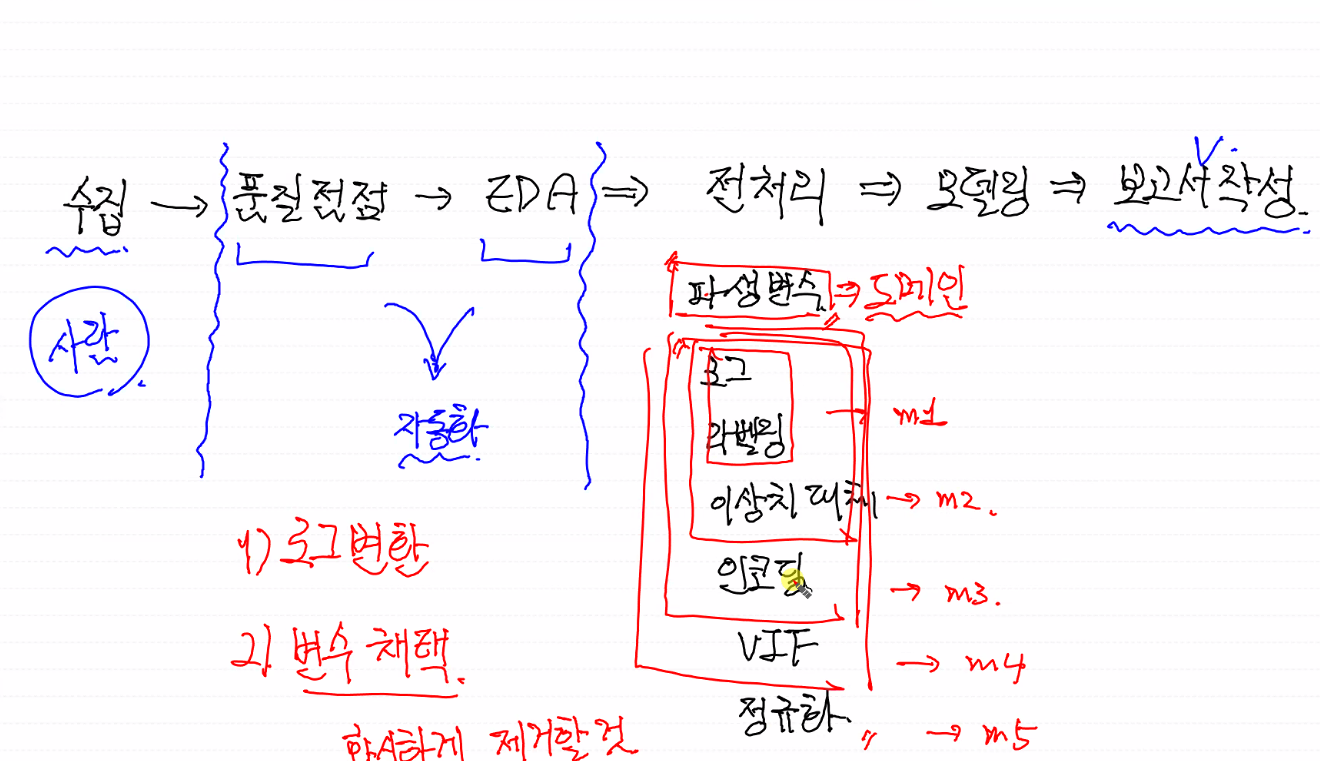

- 모델링용 전처리 때 파생변수는 자유도를 높여 할 수 있는 만큼 도메인 지식으로 만들어도 된다.
- 다만 로그 - 라벨링 - 이상치대체 - 인코딩 - VIF - 정규화 순서는 지켜야 한다. (점진적으로 모델을 5개정도 나온다)
    - 로그 - 이상치 대체 - 인코딩 - VIF 이런식으로 하나의 과정을 빼서 하는 과정들을 합하면 모델이 10개 이상이 나온다 (필요에 따라서 모델의 개수가 제곱배가 된다.)

## ipynb에서 실제 분석 수행하기

### 초기화 파일 가져오기

In [1]:
%%capture cap
%run "D:\코딩공부\4. 통계\0630\LAB08 [PBT] EDA 시작하기.ipynb"

In [2]:
print("목표변수 :", target)
print("연속형(종속변수 포함) :", continuous_cols)
print("독립변수(명목형) :", nominal_cols)
print("독립변수(연속형) :", feature_continuous)

display(df.head())          # 품질점검 완료 후 타입변환 데이터프레임
display(desc.head())        # 기술통계량 데이터프레임
display(cat_desc.head())    # 범주형 데이터 기술통계량 데이터프레임

목표변수 : MEDV
연속형(종속변수 포함) : ['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
독립변수(명목형) : ['CHAS']
독립변수(연속형) : ['CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT']


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.006,18.000,2.310,0,0.538,6.575,65.200,4.090,1,296,15.300,396.900,4.980,24.000
1,0.027,0.000,7.070,0,0.469,6.421,78.900,4.967,2,242,17.800,396.900,9.140,21.600
2,0.027,0.000,7.070,0,0.469,7.185,61.100,4.967,2,242,17.800,392.830,4.030,34.700
3,0.032,0.000,2.180,0,0.458,6.998,45.800,6.062,3,222,18.700,394.630,2.940,33.400
4,0.069,0.000,2.180,0,0.458,7.147,54.200,6.062,3,222,18.700,396.900,5.330,36.200


,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,iqr,upper_bound,lower_bound,upper_outliers,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
CRIM,506.000,3.614,8.602,0.006,0.082,0.257,3.677,88.976,13.087,large_diff,3.595,9.070,-5.311,66,0.130,0,0.000,66,0.130,5.223,right tail,37.131,leptokurtic,log1p
ZN,506.000,11.364,23.322,0.000,0.000,0.000,12.500,100.000,inf,large_diff,12.500,31.250,-18.750,68,0.134,0,0.000,68,0.134,2.226,right tail,4.032,leptokurtic,log1p
INDUS,506.000,11.137,6.860,0.460,5.190,9.690,18.100,27.740,0.149,diff,12.910,37.465,-14.175,0,0.000,0,0.000,0,0.000,0.295,symmetric,-1.234,platykurtic,none
NOX,506.000,0.555,0.116,0.385,0.449,0.538,0.624,0.871,0.031,similar,0.175,0.886,0.187,0,0.000,0,0.000,0,0.000,0.729,right tail,-0.065,platykurtic,none
RM,506.000,6.285,0.703,3.561,5.885,6.208,6.623,8.780,0.012,similar,0.738,7.731,4.778,22,0.043,8,0.016,30,0.059,0.404,symmetric,1.892,leptokurtic,none


,CHAS
count,506
unique,2
top,0
freq,471


####  데이터에 파생변수를 생성한 경우에 대한 가정
```python
df1 = df.copy()
df1.drop("NOX", inplace=True, axis=1) # 컬럼 하나 삭제 -> 파생변수 생성

for name in checkpoints:
    n = name + "(파생변수 버전)"
    fits[n] = my_ols.fit_pipeline(df1, **checkpoints[name])
```
- 딕셔너리로 반복도는 함수에서 원본과 같은 곳에 for문을 놓고 돌린다. -> 파생변수 버전으로 모델 적합 -> 또 다른 파생변수 버전이 있으면 아래에 for문 추가 

### 모듈화 기능 테스트

In [3]:
# 하나의 모델을 선택하여 학습시키고, 결과를 확인합니다.
model = my_ols.fit_pipeline(df, target)             # 데이터, 종속변수 이름
model


유의하지 않은 독립변수 제거 → AGE (p = 0.9678)
유의하지 않은 독립변수 제거 → INDUS (p = 0.6898)


In [4]:
# compare_models 는 성능표를 출력하고(report=True 기본), 최고 성능 모델을 반환한다.
my_ols.compare_models({"테스트 모델": model})

,변수수,R2(모델척도),Adj.R2,AIC,BIC,R2(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
테스트 모델,11,0.741,0.735,3021.726,3072.445,0.741,4.680,3.272,0.000


### 파이프라인 구성 (실전 분석용)

In [5]:
checkpoints = {
    "0_기준선":    dict(),
    "1_로그변환":   dict(log=True),
    "2_이상치대체": dict(log=True, outlier=True),
    "3_공선성제거": dict(log=True, outlier=True, vif=True),
    "4_스케일링":   dict(log=True, outlier=True, vif=True, scale=True),
}

fits = {}

for name in checkpoints:
    fits[name] = my_ols.fit_pipeline(df, target, **checkpoints[name])

# compare_models 는 성능표를 출력하고, 성능이 가장 좋은 모델을 반환한다.
final_fit = my_ols.compare_models(fits)
print(f"best model: {final_fit.name_}")


유의하지 않은 독립변수 제거 → AGE (p = 0.9678)
유의하지 않은 독립변수 제거 → INDUS (p = 0.6898)

유의하지 않은 독립변수 제거 → ZN (p = 0.9968)
유의하지 않은 독립변수 제거 → B (p = 0.7881)
유의하지 않은 독립변수 제거 → INDUS (p = 0.5519)
유의하지 않은 독립변수 제거 → AGE (p = 0.2722)

유의하지 않은 독립변수 제거 → ZN (p = 0.9069)
유의하지 않은 독립변수 제거 → B (p = 0.8131)
유의하지 않은 독립변수 제거 → INDUS (p = 0.5008)
유의하지 않은 독립변수 제거 → AGE (p = 0.3039)

완료! 남은 변수: ['AGE', 'B', 'CRIM', 'DIS', 'INDUS', 'LSTAT', 'NOX', 'PTRATIO', 'RAD', 'RM', 'TAX', 'ZN']
최대 VIF = 7.08

유의하지 않은 독립변수 제거 → ZN (p = 0.9069)
유의하지 않은 독립변수 제거 → B (p = 0.8131)
유의하지 않은 독립변수 제거 → INDUS (p = 0.5008)
유의하지 않은 독립변수 제거 → AGE (p = 0.3039)

완료! 남은 변수: ['AGE', 'B', 'CRIM', 'DIS', 'INDUS', 'LSTAT', 'NOX', 'PTRATIO', 'RAD', 'RM', 'TAX', 'ZN']
최대 VIF = 7.08

유의하지 않은 독립변수 제거 → ZN (p = 0.9069)
유의하지 않은 독립변수 제거 → B (p = 0.8131)
유의하지 않은 독립변수 제거 → INDUS (p = 0.5008)
유의하지 않은 독립변수 제거 → AGE (p = 0.3039)


,변수수,R2(모델척도),Adj.R2,AIC,BIC,R2(원본척도),RMSE,MAE,Gap(%)
모델,,,,,,,,,
1_로그변환,9,0.792,0.789,-301.461,-259.196,0.789,4.215,2.973,0.000
2_이상치대체,9,0.791,0.787,-297.591,-255.326,0.787,4.237,2.982,0.510
3_공선성제거,9,0.791,0.787,-297.591,-255.326,0.787,4.237,2.982,0.510
4_스케일링,9,0.791,0.787,-297.591,-255.326,0.787,4.237,2.982,0.510
0_기준선,11,0.741,0.735,3021.726,3072.445,0.741,4.680,3.272,11.010


best model: 1_로그변환


### best model에 대한 성능 보고 및 가정 확인

## 최종 모델: 1_로그변환

### ▶︎ 성능 보고

#### 1) 모형 적합도

**Note. n = 506. F(9, 496) = 210.41, p < 0.001, R^2 = 0.792, Adj.R^2 = 0.789, Durbin-Watson = 1.037**

log1p(MEDV)를 종속변수로, log1p(CRIM), CHAS, NOX, RM, log1p(DIS), log1p(RAD), TAX, PTRATIO, log1p(LSTAT)(을)를 독립변수로한 다중선형회귀분석 결과, 모형은 통계적으로 유의하였다.

> F(9, 496) = 210.41, p < 0.001, R^2 = 0.792.

즉, log1p(CRIM), CHAS, NOX, RM, log1p(DIS), log1p(RAD), TAX, PTRATIO, log1p(LSTAT)는 log1p(MEDV)의 약 79.24%를 설명하는 것으로 나타났다.

#### 2) 회귀계수 보고표

,종속변수,독립변수,B,표준오차,표준오차(HC3),β,t,t(HC3),유의확률,유의확률(HC3),공차,VIF
0,MEDV,LSTAT,-0.414,0.024,0.036,-0.576,-16.903,-11.433,0.000,0.000,0.360,2.777
1,MEDV,CRIM,-0.152,0.019,0.025,-0.401,-8.094,-6.083,0.000,0.000,0.171,5.857
2,MEDV,RAD,0.166,0.025,0.025,0.323,6.678,6.553,0.000,0.000,0.179,5.585
3,MEDV,DIS,-0.269,0.035,0.040,-0.288,-7.675,-6.799,0.000,0.000,0.298,3.353
4,MEDV,PTRATIO,-0.030,0.005,0.004,-0.170,-6.718,-7.687,0.000,0.000,0.653,1.532
5,MEDV,NOX,-0.556,0.141,0.159,-0.167,-3.954,-3.502,0.000,0.001,0.236,4.239
6,MEDV,TAX,-0.000,0.000,0.000,-0.138,-2.799,-2.270,0.005,0.024,0.173,5.774
7,MEDV,RM,0.066,0.016,0.024,0.119,4.230,2.753,0.000,0.006,0.526,1.900
8,MEDV,CHAS,0.095,0.032,0.038,0.063,2.969,2.533,0.003,0.012,0.944,1.060


#### 3) 영향력 순위 시각화 (표준화 계수 β)

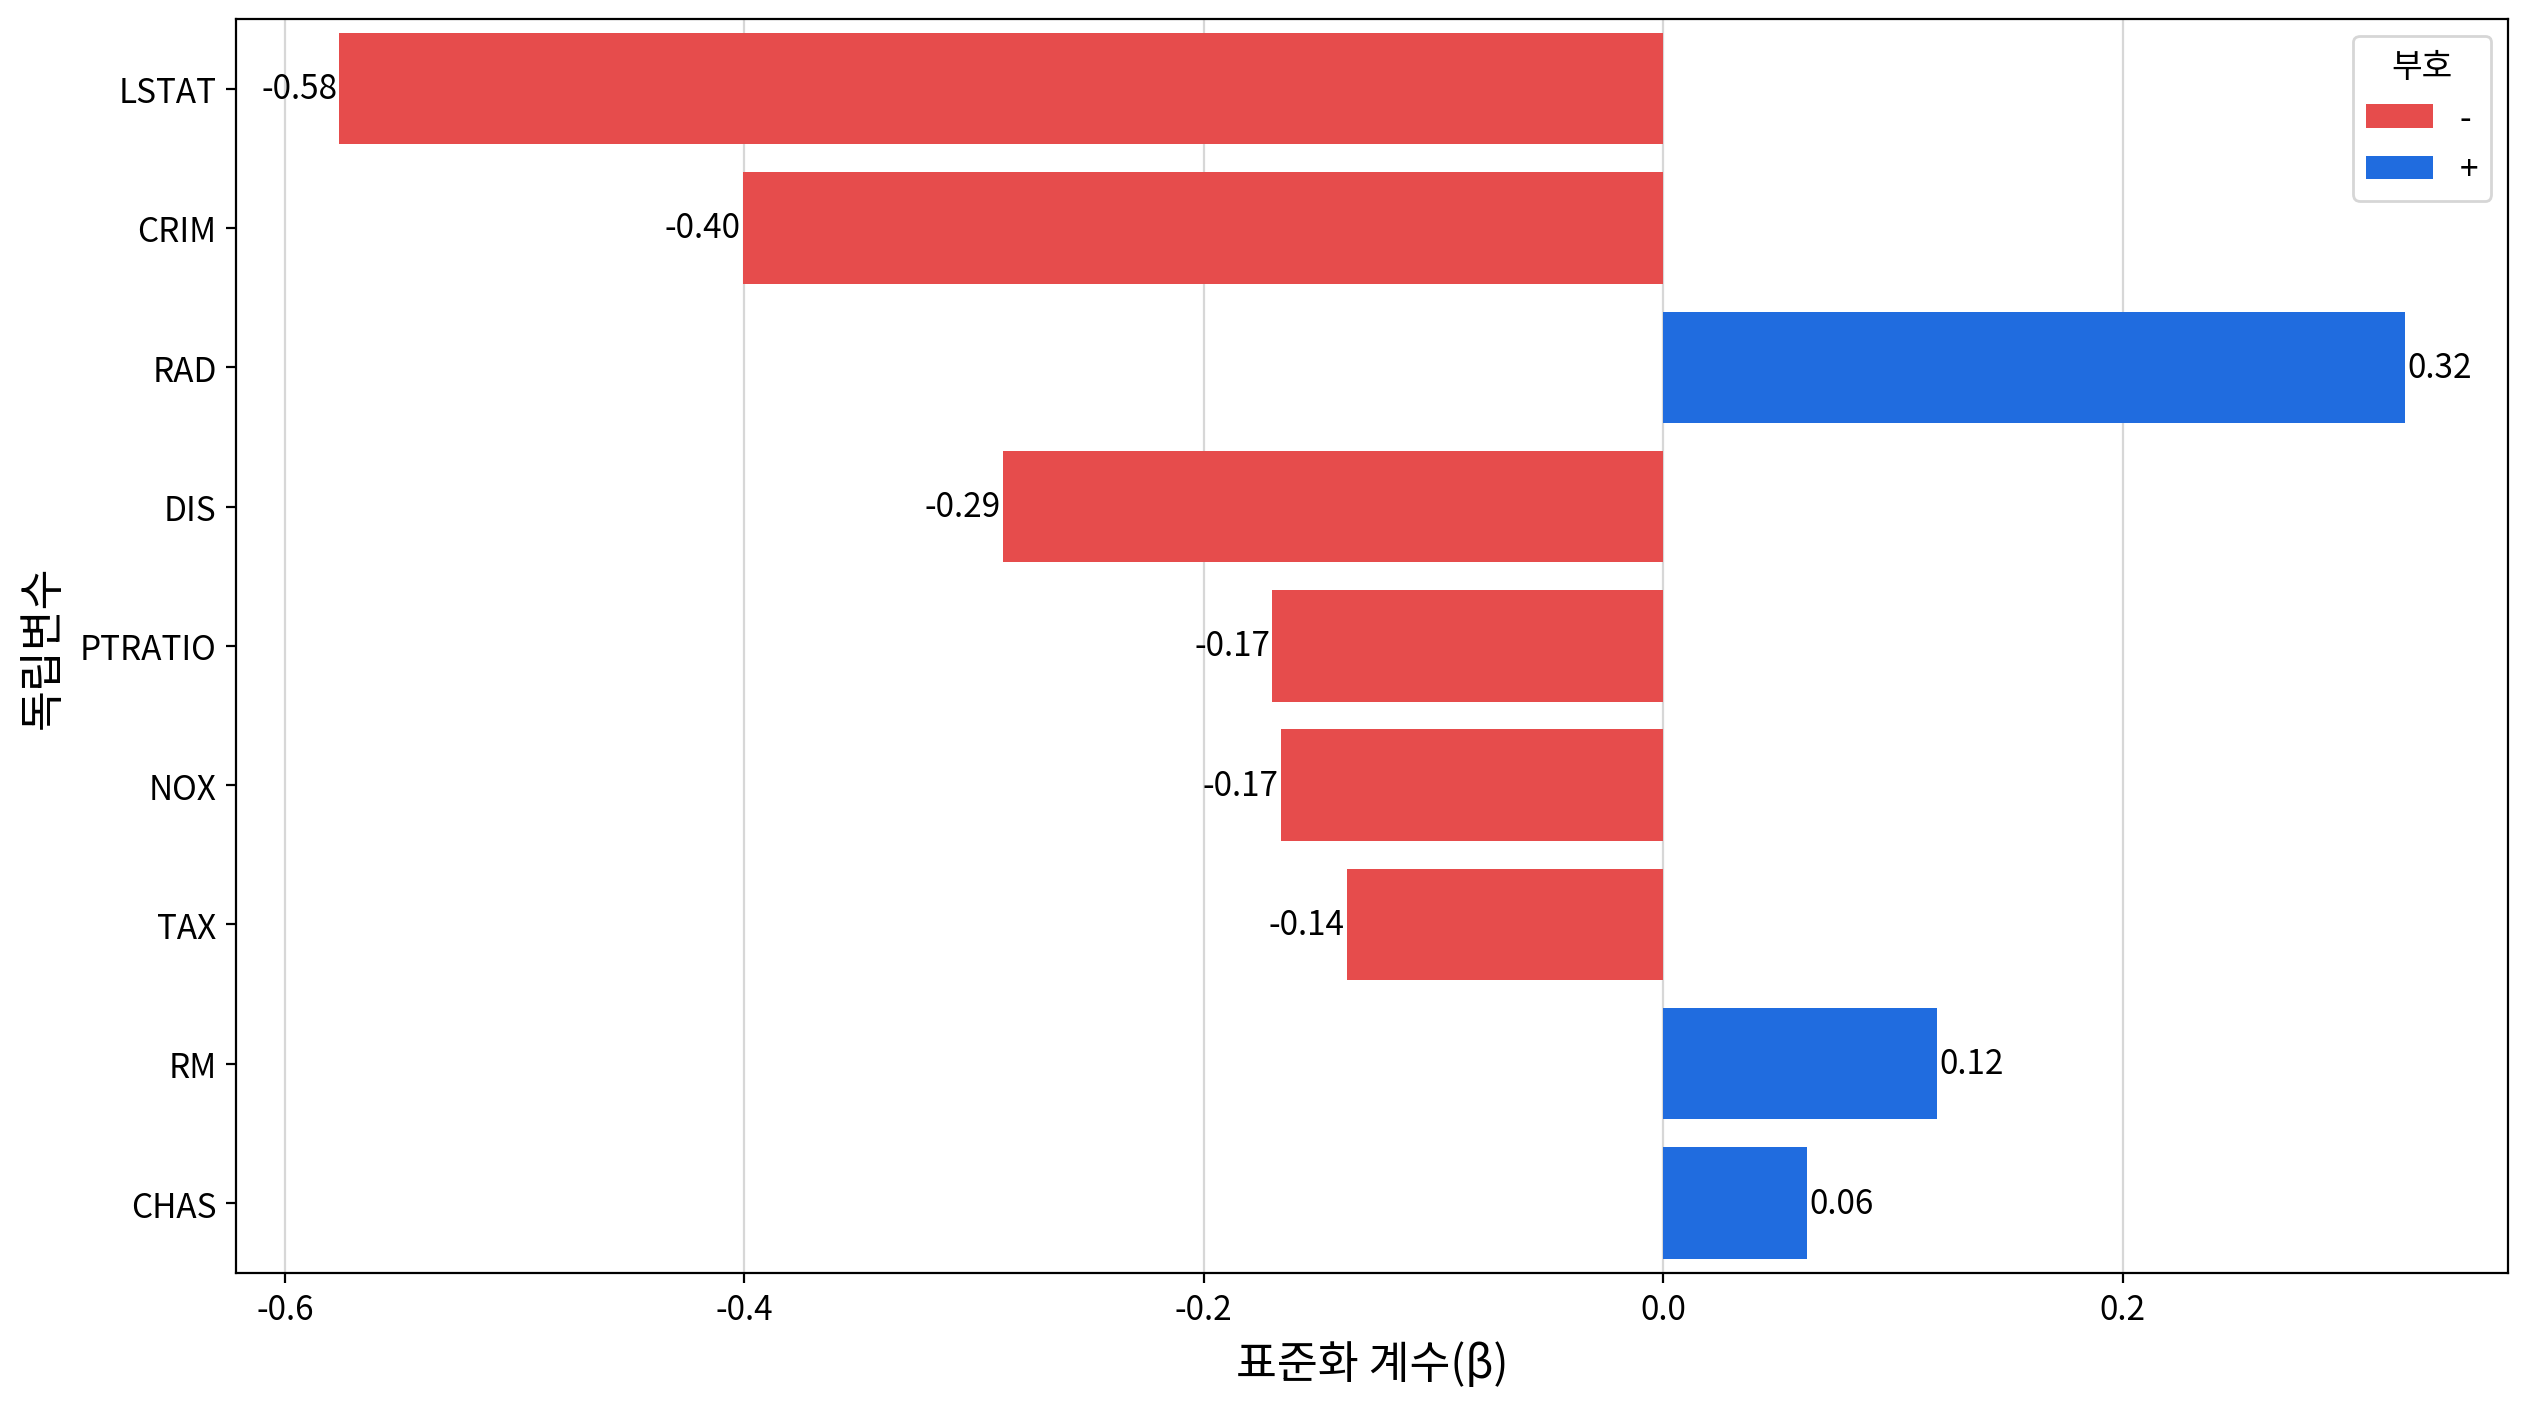

#### 4) 회귀계수 해석 문장

- **CRIM**의 회귀계수는 **B = -0.15**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -6.08**, **p < .001**) 즉, **(1+CRIM)**가 1% 증가**할 때 **(1+MEDV)**는 평균적으로 약 **0.15%감소**하는 것으로 해석된다.
- **CHAS**의 회귀계수는 **B = 0.1**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = 2.53**, **p = .012**) 즉, CHAS가 **1 증가**할 때 **(1+MEDV)**는 평균적으로 약 **9.99%증가**하는 것으로 해석된다.
- **NOX**의 회귀계수는 **B = -0.56**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -3.5**, **p < .001**) 즉, NOX가 **1 증가**할 때 **(1+MEDV)**는 평균적으로 약 **42.66%감소**하는 것으로 해석된다.
- **RM**의 회귀계수는 **B = 0.07**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = 2.75**, **p = .006**) 즉, RM가 **1 증가**할 때 **(1+MEDV)**는 평균적으로 약 **6.79%증가**하는 것으로 해석된다.
- **DIS**의 회귀계수는 **B = -0.27**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -6.8**, **p < .001**) 즉, **(1+DIS)**가 1% 증가**할 때 **(1+MEDV)**는 평균적으로 약 **0.27%감소**하는 것으로 해석된다.
- **RAD**의 회귀계수는 **B = 0.17**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = 6.55**, **p < .001**) 즉, **(1+RAD)**가 1% 증가**할 때 **(1+MEDV)**는 평균적으로 약 **0.17%증가**하는 것으로 해석된다.
- **TAX**의 회귀계수는 **B = -0.0**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -2.27**, **p = .024**) 즉, TAX가 **1 증가**할 때 **(1+MEDV)**는 평균적으로 약 **0.03%감소**하는 것으로 해석된다.
- **PTRATIO**의 회귀계수는 **B = -0.03**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -7.69**, **p < .001**) 즉, PTRATIO가 **1 증가**할 때 **(1+MEDV)**는 평균적으로 약 **2.99%감소**하는 것으로 해석된다.
- **LSTAT**의 회귀계수는 **B = -0.41**으로 나타났으며, 이는 **MEDV**에 유의한 요인임을 의미한다. (**t(496) = -11.43**, **p < .001**) 즉, **(1+LSTAT)**가 1% 증가**할 때 **(1+MEDV)**는 평균적으로 약 **0.41%감소**하는 것으로 해석된다.

> ※ **t** **유의확률**은 등분산 가정이 충족되지 않은 경우를 대비해 **HC3 로버스트 표준오차**로 계산한 값이다. 회귀계수(B)와 효과크기 해석은 일반 OLS와 동일하며, 표준오차와 이분산에 강건하게 보정되어 유의성 판정이 달라질 수 있다.

> ※ **log1p**(=ln(1+·))의 % 해석은 변수 자체가 아니라 **(1+변수)** 기준이며, 값이 클 때만 위 근사가 성립한다(0·작은 값 구간에서는 원본처럼 동작해 부정확). 이 구간에서는 부호·유의성 중심으로 해석하거나 예측값을 expm1로 원 척도에서 비교한다.

---

### ▶︎ 회귀모형 가정 검정

#### 1) 선형성 검정

,statistic,p-value,linearity,result
Ramsey RESET,5.635,0.018,False,대립가설 채택 → 선형성 위배(곡선 관계 존재)


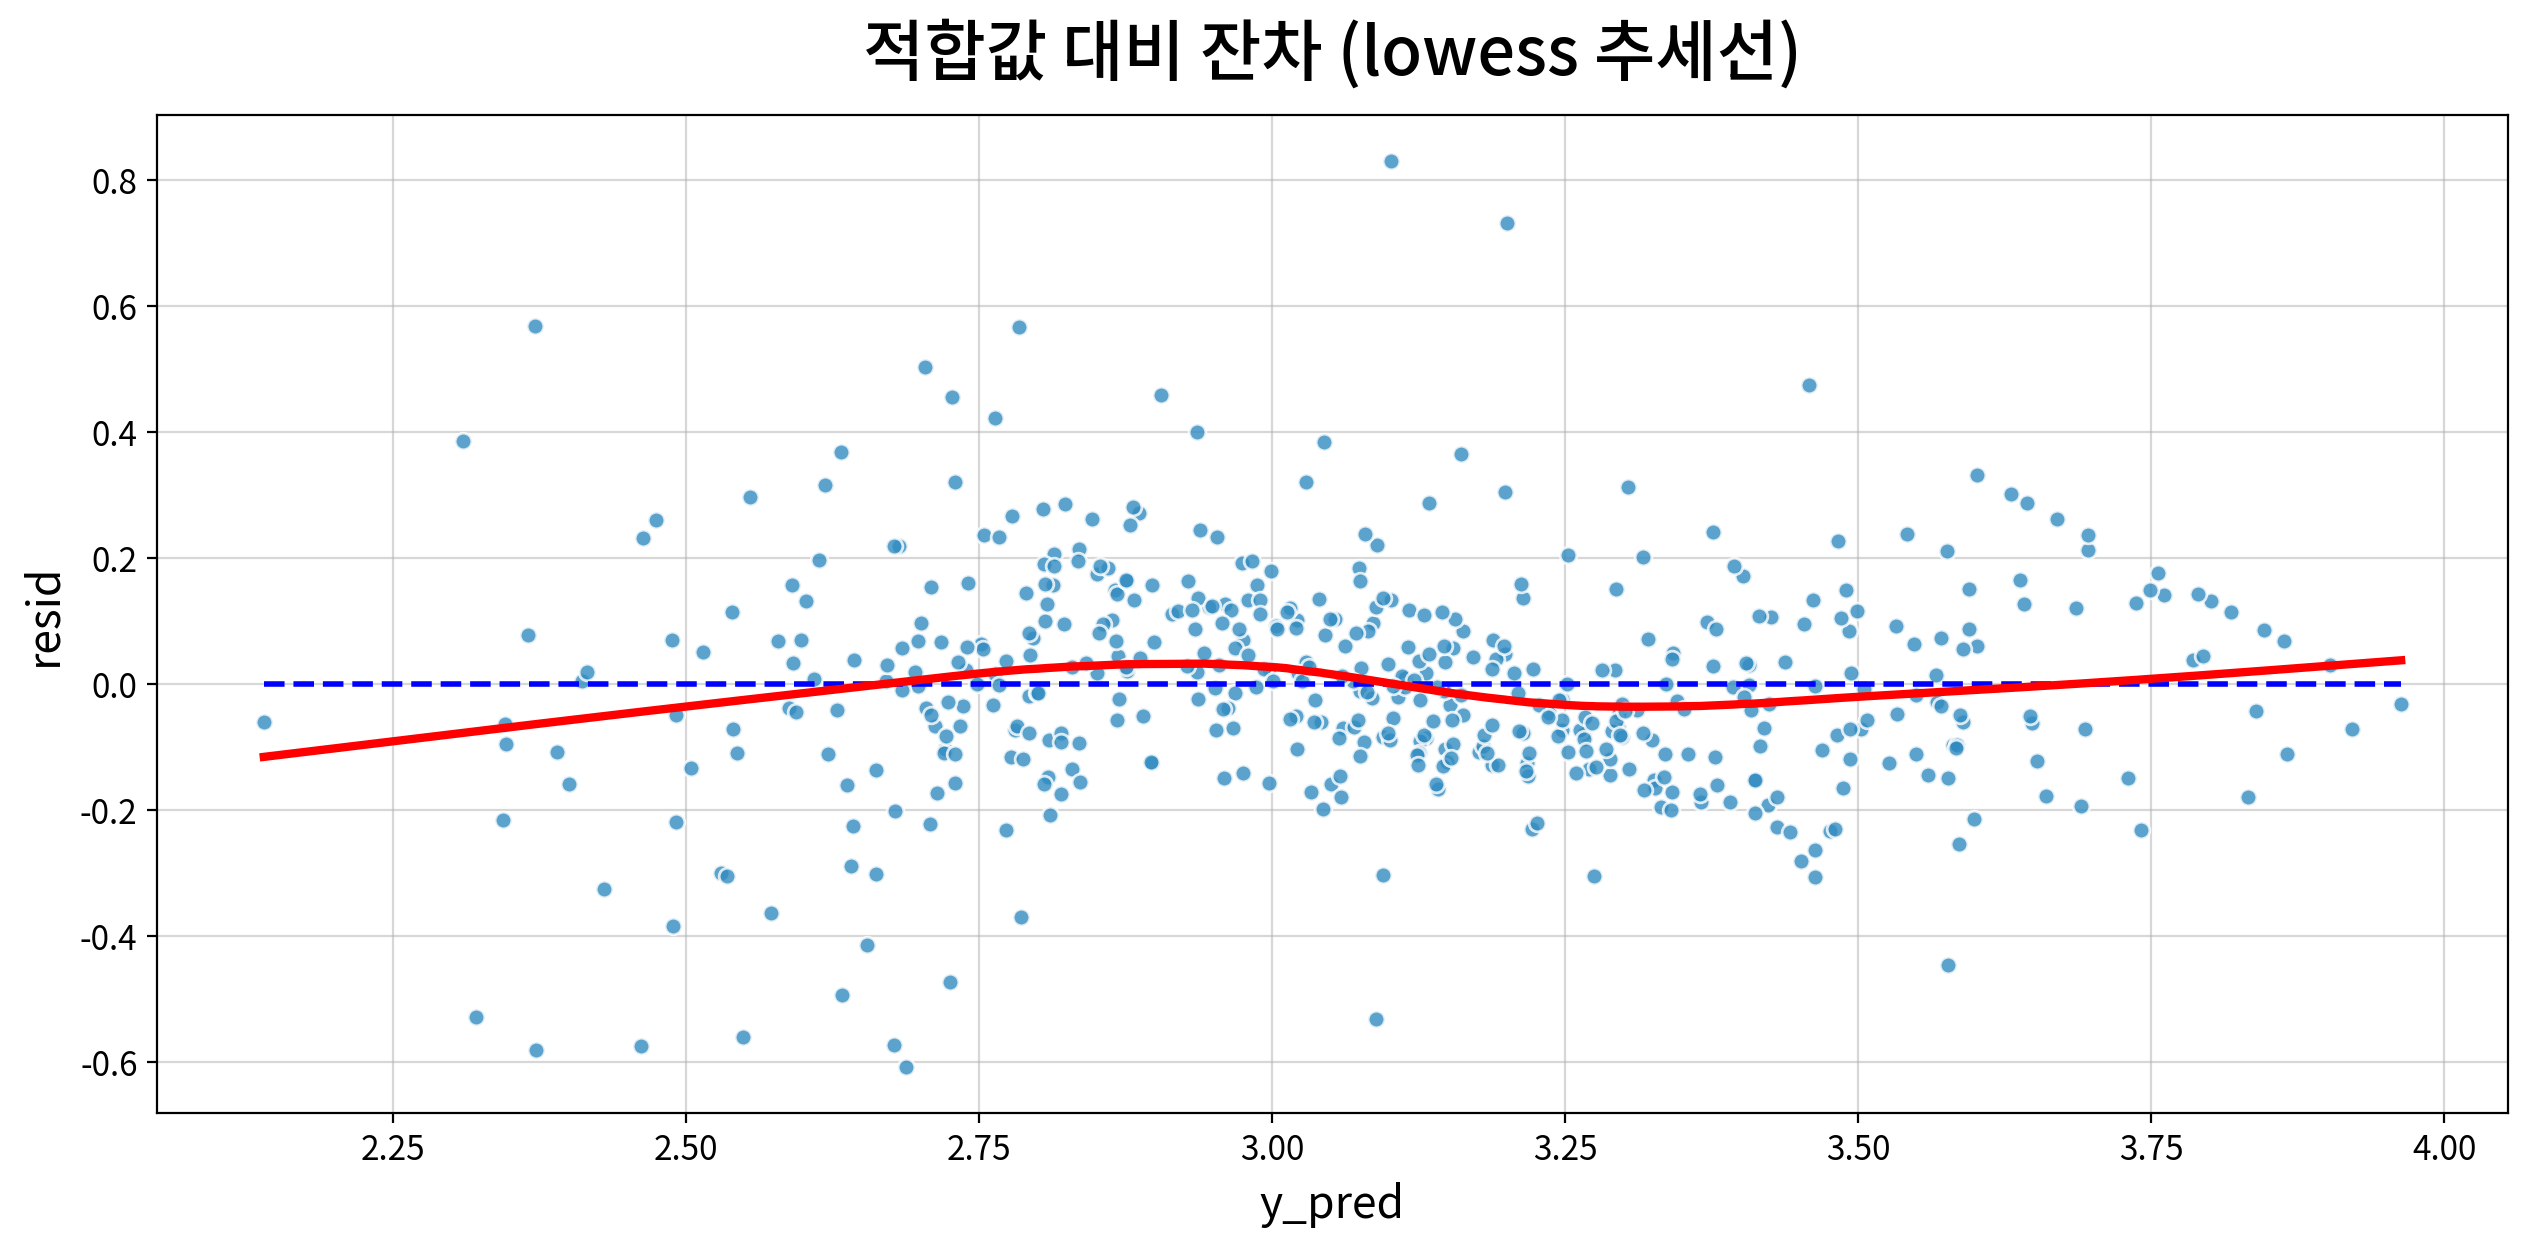

#### 2) 정규성 검정

,statistic,p-value,normality,result
Kolmogorov-Smirnov,0.060,0.049,False,대립가설 채택 → 정규성 위배


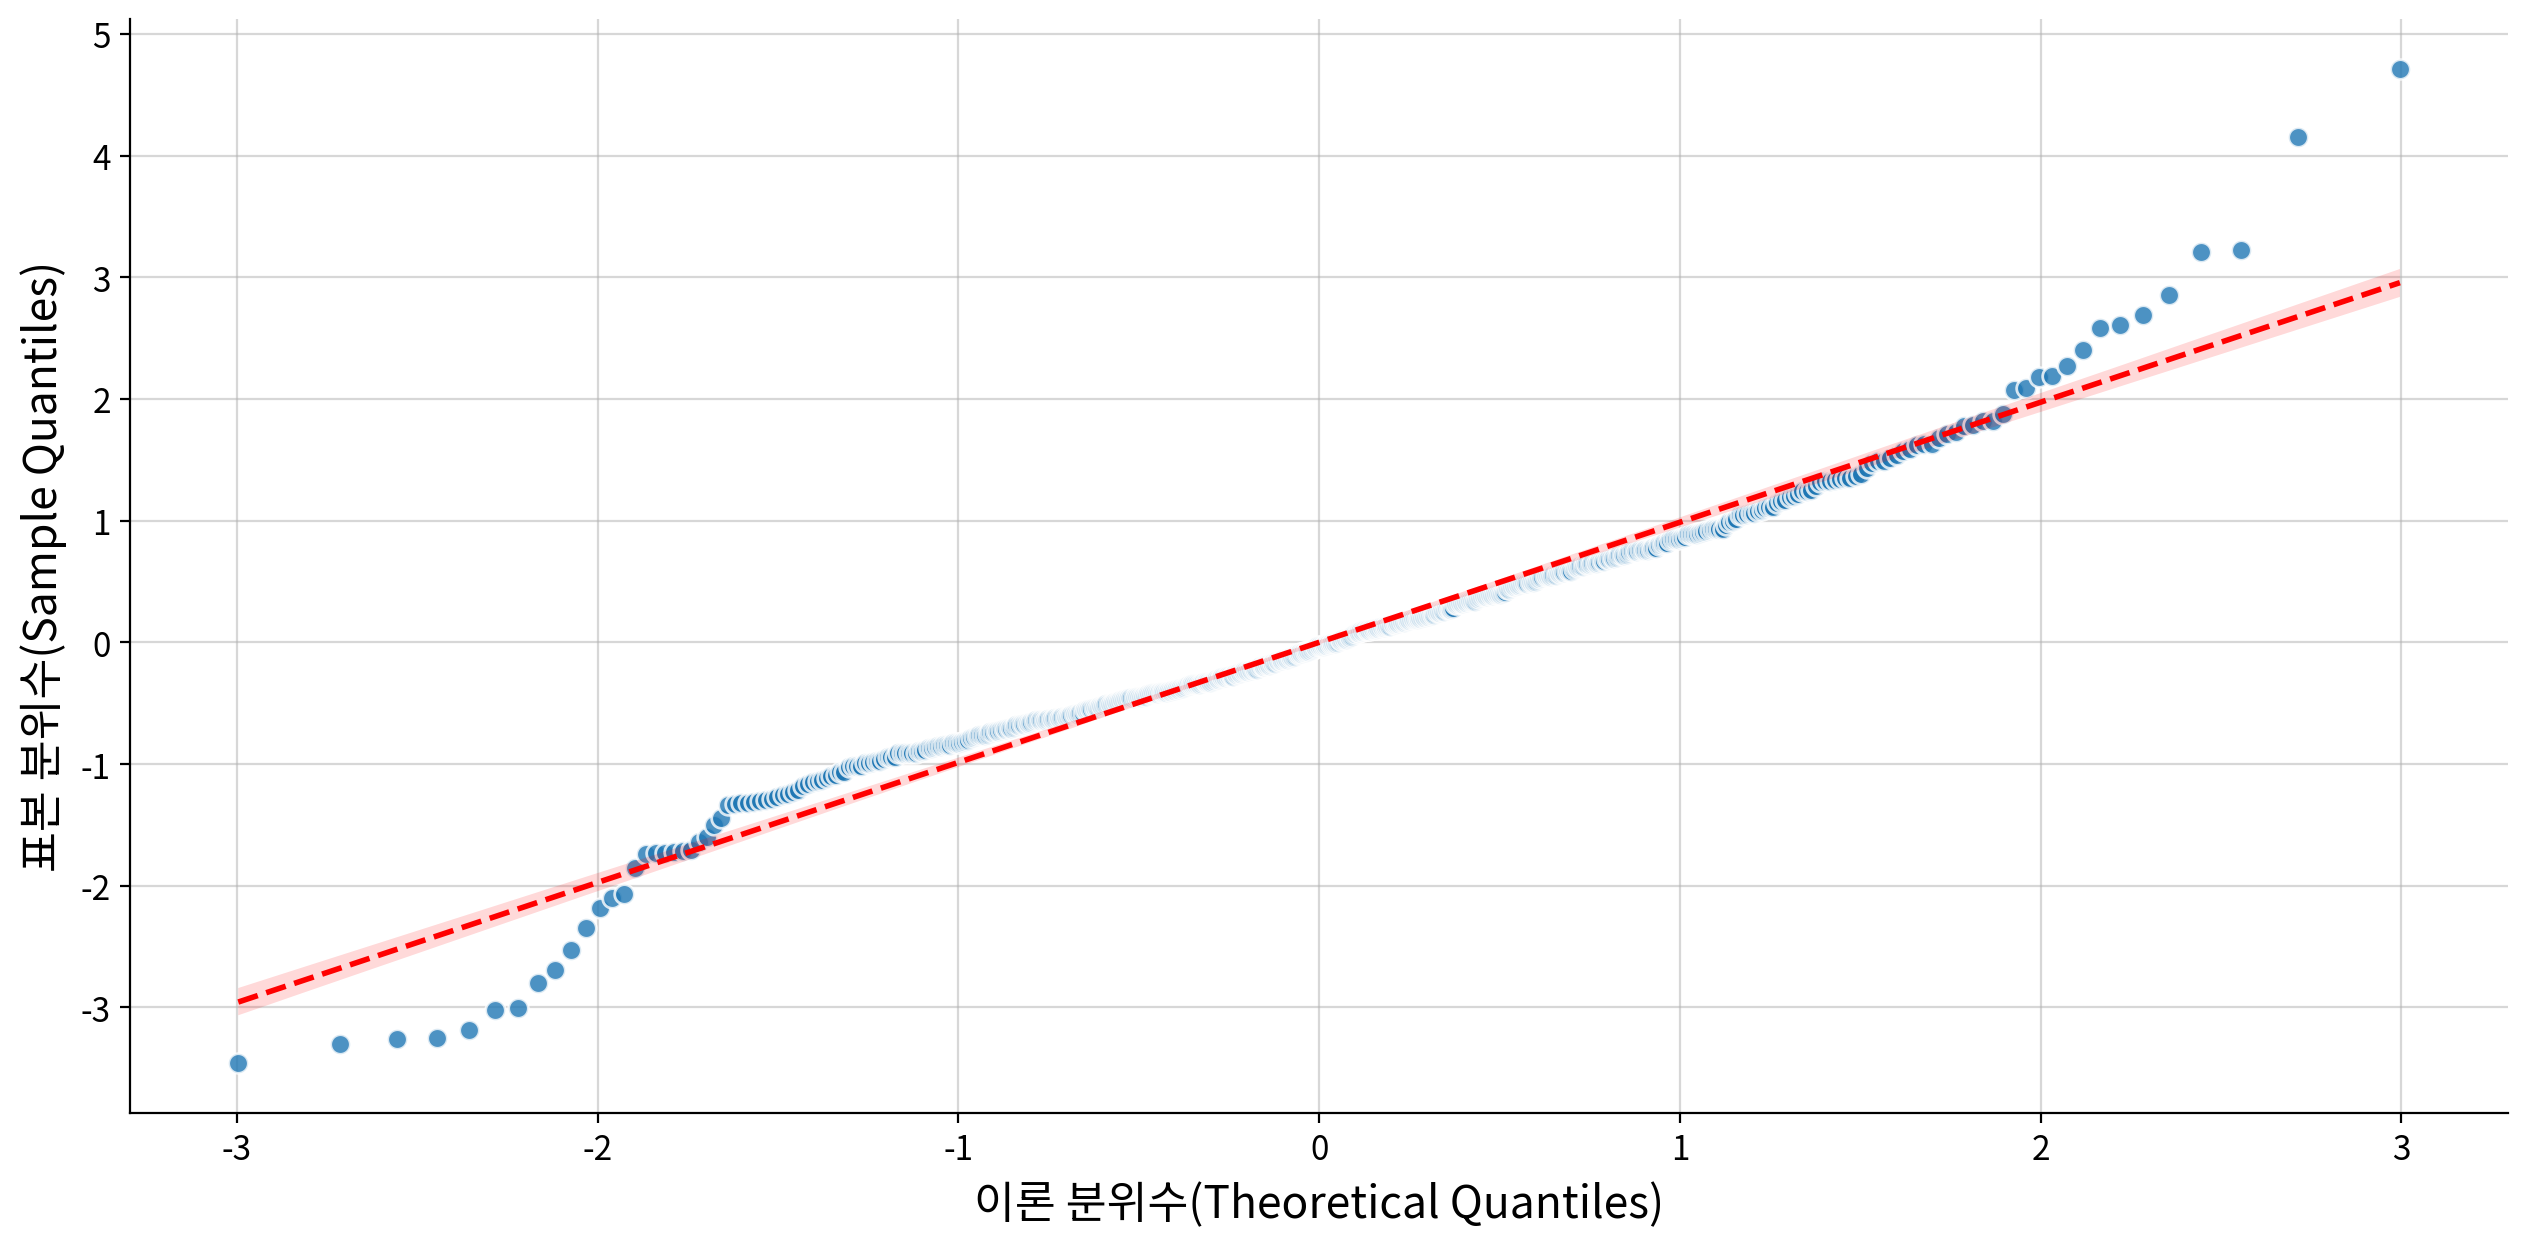

,기대(%),허용범위(%),실제(%),판정
구간,,,,
±1√MSE,68.000,64~72,77.270,위배
±2√MSE,95.000,93~97,94.470,충족
±3√MSE,99.700,99~100,98.220,위배


√MSE = 0.18 · 구간 규칙 판정: 정규성 위배


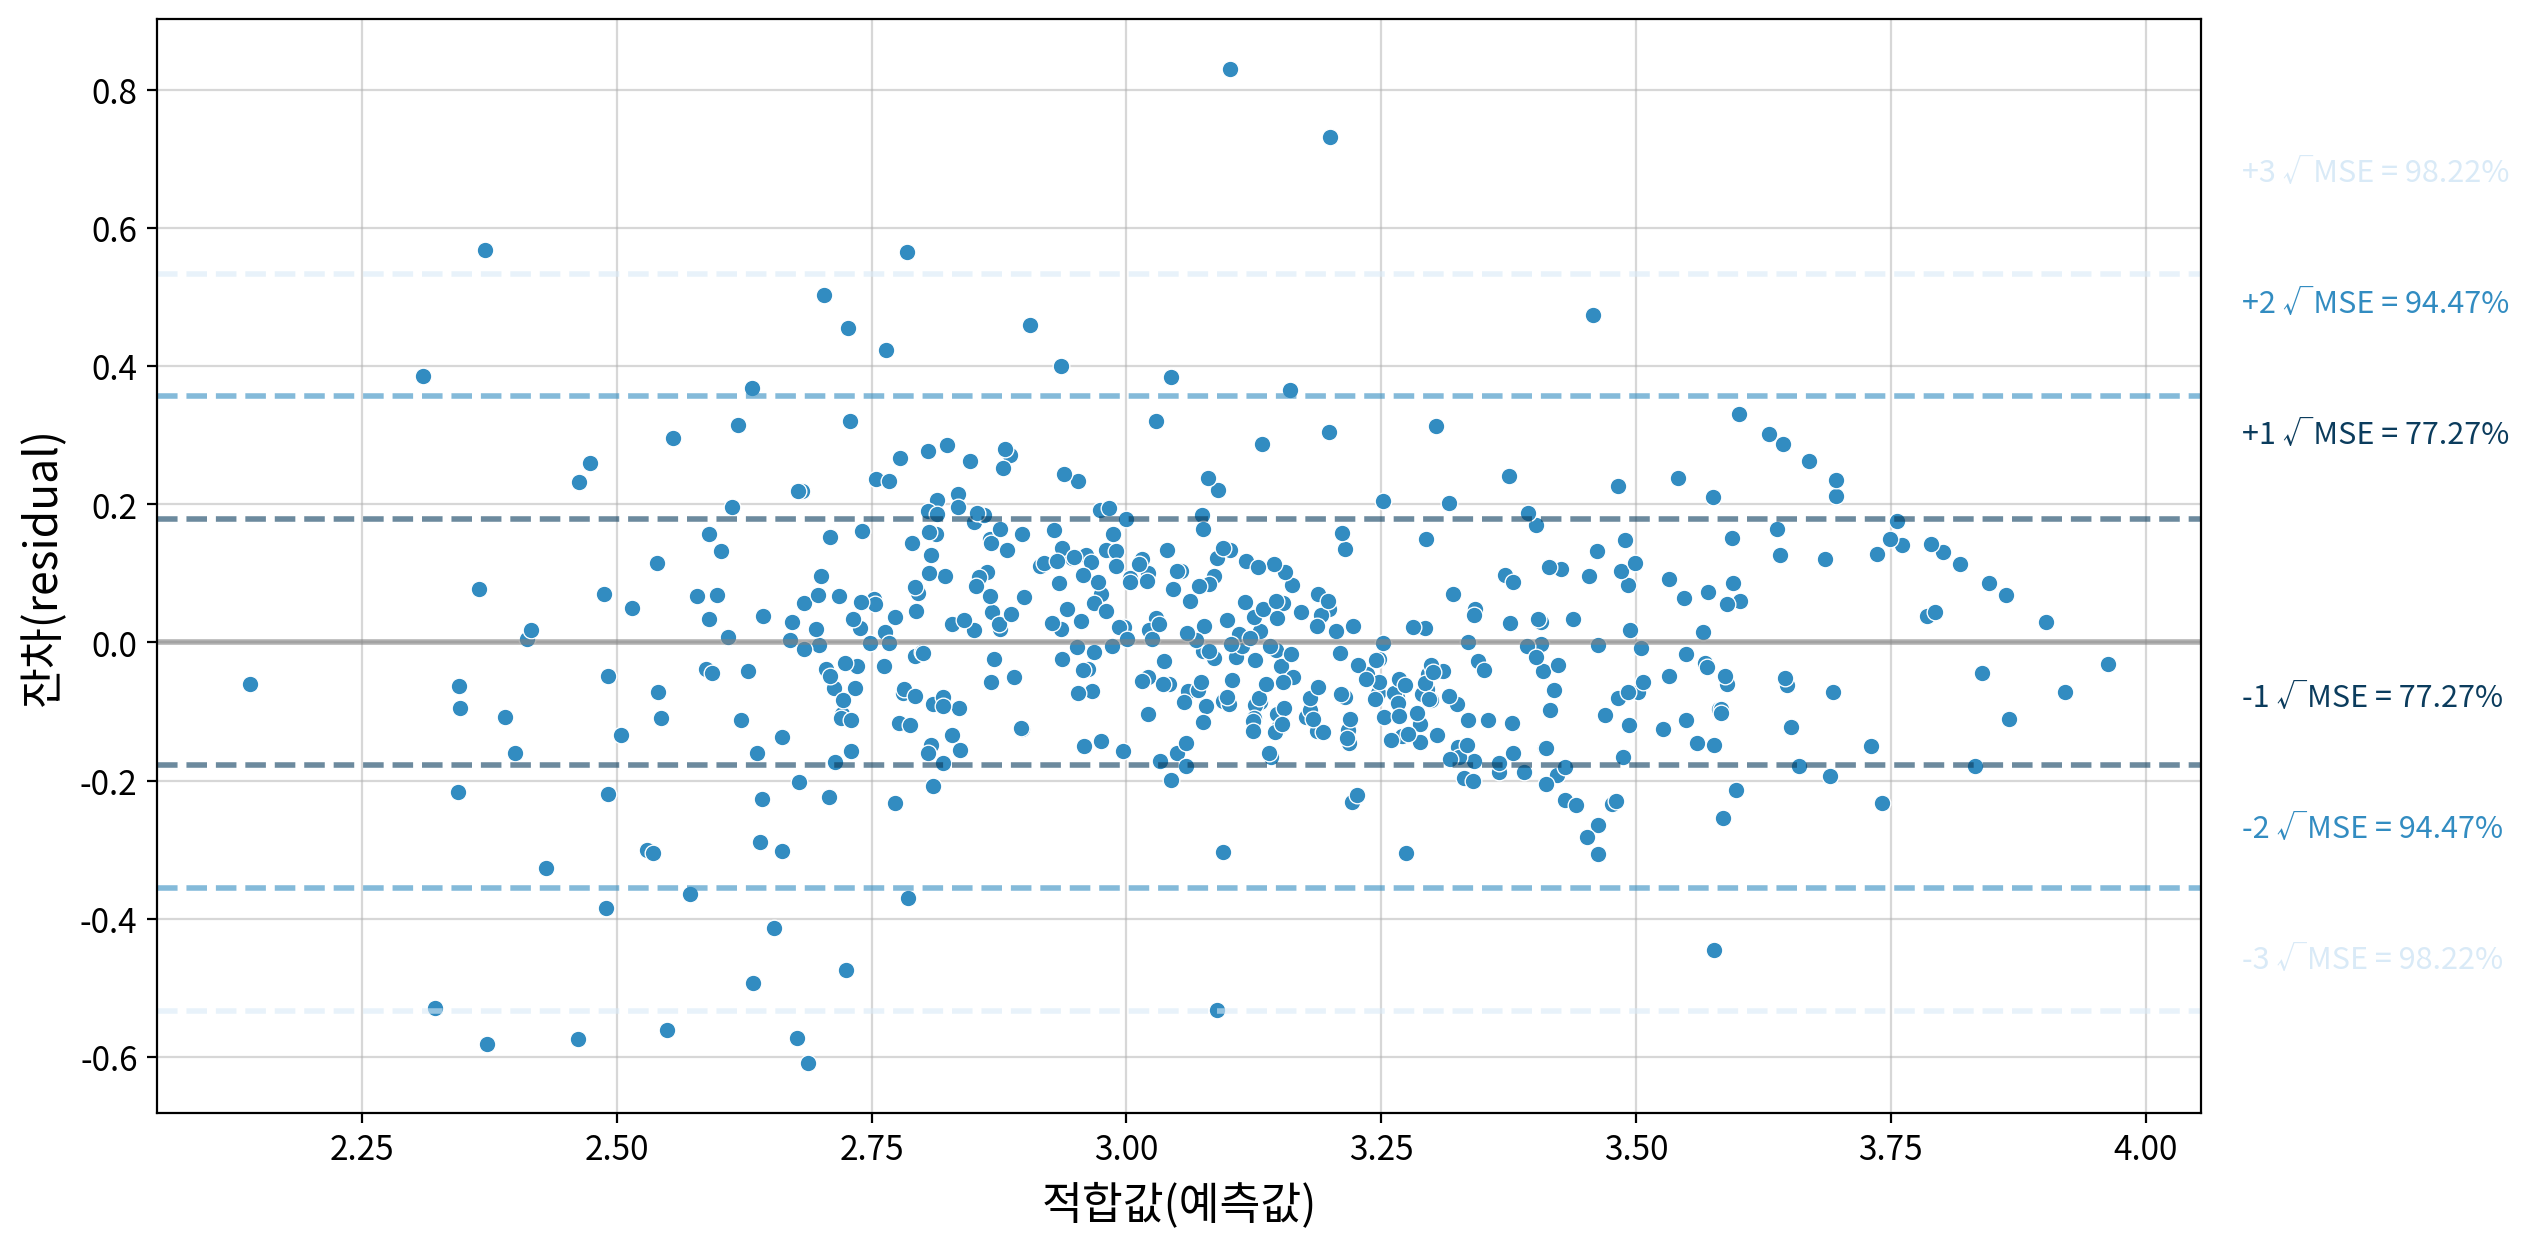

#### 3) 등분산성 검정

,LM statistic,LM p-value,F statistic,F p-value,homoscedasticity,result
Breusch-Pagan,77.414,0.000,9.954,0.000,False,대립가설 채택 → 등분산 아님


#### 4) 독립성 검정

,statistic,independence,result
Durbin-Watson,1.037,False,독립성 위반 (양(+)의 자기상관)


In [6]:
my_ols.report_model(final_fit)